In [115]:
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [116]:
df=pd.read_csv("Student Depression Detection Dataset/Student_Depression_Dataset.csv")
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [117]:
df.shape

(4464, 13)

### No columns to remove 

In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


In [119]:
df=pd.get_dummies(data=df,columns=['Relationship_status','Marital_status','Living_style','friend_circle','Health_condition','Home_division'],dtype=int)
df.head()

,Gender,Age,Family_background,Current_semester,CGPA,Cost_without_study,Depression,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,...,Health_condition_Good,Health_condition_Normal,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,Female,22,Middle class,8,3.43,10113,Yes,0,0,1,...,0,0,0,1,0,0,0,0,0,0
1,Male,19,Middle class,2,3.70,13815,Yes,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,Male,23,Middle class,8,3.28,15450,Yes,0,0,1,...,0,0,0,0,1,0,0,0,0,0
3,Male,20,Middle class,2,3.77,17413,No,1,0,0,...,1,0,0,0,1,0,0,0,0,0
4,Female,21,Middle class,1,4.00,16693,Yes,0,0,1,...,0,0,0,0,1,0,0,0,0,0


In [120]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 4464 non-null   str    
 1   Age                                    4464 non-null   int64  
 2   Family_background                      4464 non-null   str    
 3   Current_semester                       4464 non-null   int64  
 4   CGPA                                   4464 non-null   float64
 5   Cost_without_study                     4464 non-null   int64  
 6   Depression                             4464 non-null   str    
 7   Relationship_status_Complicated        4464 non-null   int64  
 8   Relationship_status_In a Relationship  4464 non-null   int64  
 9   Relationship_status_Single             4464 non-null   int64  
 10  Marital_status_Married                 4464 non-null   int64  
 11  Marital_status_

In [121]:
df['Family_background'].value_counts()

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

In [122]:
df['Gender'].value_counts()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

In [123]:
Family_map={'Rich class': 1,
            'Middle class':2,
            'Lower Middle class':3}

Gender_map={'Female':0,
            'Male':1}

In [124]:
df['Family_background']=df['Family_background'].map(Family_map)
df['Gender']=df['Gender'].map(Gender_map)
df.head()

,Gender,Age,Family_background,Current_semester,CGPA,Cost_without_study,Depression,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,...,Health_condition_Good,Health_condition_Normal,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,0,22,2,8,3.43,10113,Yes,0,0,1,...,0,0,0,1,0,0,0,0,0,0
1,1,19,2,2,3.70,13815,Yes,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,1,23,2,8,3.28,15450,Yes,0,0,1,...,0,0,0,0,1,0,0,0,0,0
3,1,20,2,2,3.77,17413,No,1,0,0,...,1,0,0,0,1,0,0,0,0,0
4,0,21,2,1,4.00,16693,Yes,0,0,1,...,0,0,0,0,1,0,0,0,0,0


In [125]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 4464 non-null   int64  
 1   Age                                    4464 non-null   int64  
 2   Family_background                      4464 non-null   int64  
 3   Current_semester                       4464 non-null   int64  
 4   CGPA                                   4464 non-null   float64
 5   Cost_without_study                     4464 non-null   int64  
 6   Depression                             4464 non-null   str    
 7   Relationship_status_Complicated        4464 non-null   int64  
 8   Relationship_status_In a Relationship  4464 non-null   int64  
 9   Relationship_status_Single             4464 non-null   int64  
 10  Marital_status_Married                 4464 non-null   int64  
 11  Marital_status_

## Outlier detection

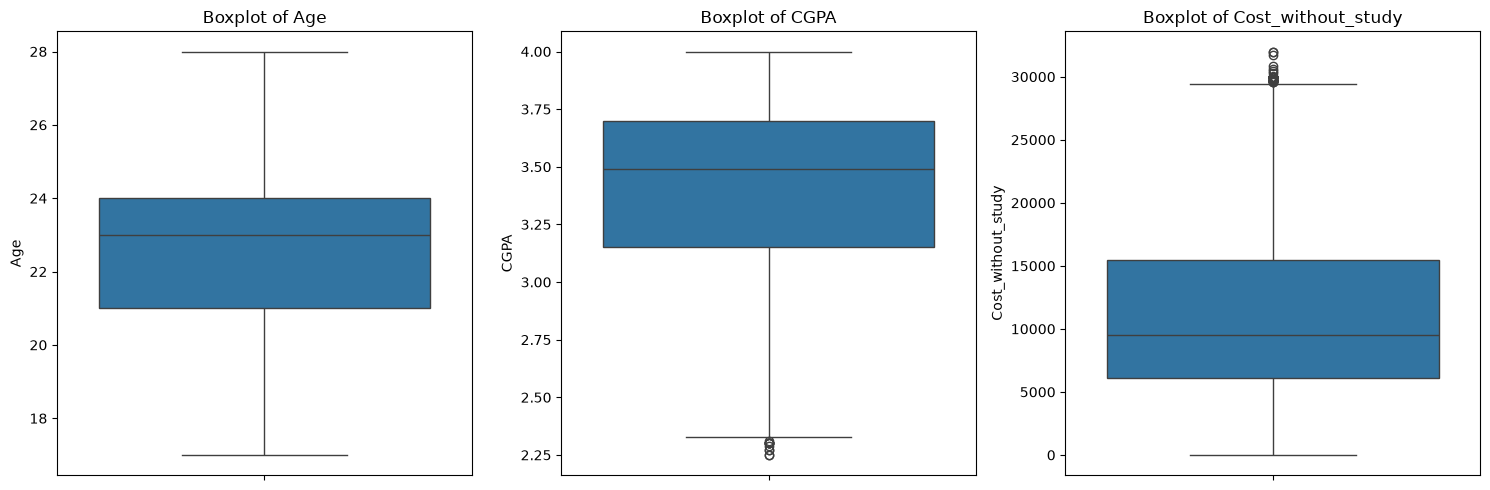

Age: 0 outliers
CGPA: 12 outliers
Cost_without_study: 36 outliers


In [126]:
# Boxplots for numerical columns where extreme values are possible
outlier_columns = ['Age', 'CGPA', 'Cost_without_study']

fig, axes = plt.subplots(1, len(outlier_columns), figsize=(15, 5))

for ax, column in zip(axes, outlier_columns):
    sns.boxplot(data=df, y=column, ax=ax)
    ax.set_title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

# IQR-based outlier counts
for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()
    print(f'{column}: {outlier_count} outliers')

In [127]:
# Remove IQR-detected outliers from the numerical columns
outlier_columns = ['Age', 'CGPA', 'Cost_without_study']
rows_to_keep = pd.Series(True, index=df.index)

for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    rows_to_keep &= df[column].between(lower_bound, upper_bound)

rows_before = df.shape[0]
df = df.loc[rows_to_keep].reset_index(drop=True)
rows_removed = rows_before - df.shape[0]

print(f'Rows before removal: {rows_before}')
print(f'Rows removed: {rows_removed}')
print(f'Rows after removal: {df.shape[0]}')

Rows before removal: 4464
Rows removed: 48
Rows after removal: 4416


In [128]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4416 entries, 0 to 4415
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 4416 non-null   int64  
 1   Age                                    4416 non-null   int64  
 2   Family_background                      4416 non-null   int64  
 3   Current_semester                       4416 non-null   int64  
 4   CGPA                                   4416 non-null   float64
 5   Cost_without_study                     4416 non-null   int64  
 6   Depression                             4416 non-null   str    
 7   Relationship_status_Complicated        4416 non-null   int64  
 8   Relationship_status_In a Relationship  4416 non-null   int64  
 9   Relationship_status_Single             4416 non-null   int64  
 10  Marital_status_Married                 4416 non-null   int64  
 11  Marital_status_

Depression
No     3228
Yes    1188
Name: count, dtype: int64


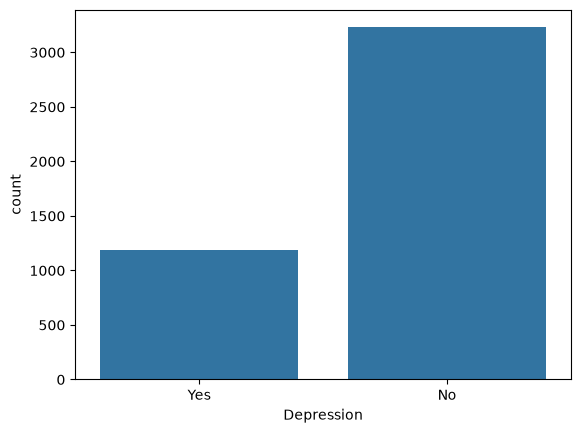

In [129]:
sns.countplot(data=df, x='Depression')
print(df['Depression'].value_counts())

## splitting target and predictors 

In [130]:
X=df.drop(columns=['Depression'])
Y=df['Depression']

## splitting train and test 

In [131]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)


(3532, 28)
(884, 28)
(3532,)
(884,)


## Scaling 

In [132]:
from sklearn.preprocessing import StandardScaler


In [133]:
ss=StandardScaler()
X_train=pd.DataFrame(ss.fit_transform(X_train))
X_test=pd.DataFrame(ss.transform(X_test))


## Getting the model 

In [134]:
from sklearn.linear_model import LogisticRegression


In [135]:
model = LogisticRegression()
model.fit(X_train, Y_train)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [136]:
predictedvalue = model.predict(X_test)
predictedtocheck = model.predict(X_train)

## Evaluation

In [137]:
from sklearn.metrics import(
accuracy_score,
confusion_matrix,
classification_report)

In [138]:
print("Metrics of Y_Test: ")
print(accuracy_score(Y_test,predictedvalue))
print(confusion_matrix(Y_test,predictedvalue))
print(classification_report(Y_test,predictedvalue))


Metrics of Y_Test: 
0.9762443438914027
[[643   7]
 [ 14 220]]
              precision    recall  f1-score   support

          No       0.98      0.99      0.98       650
         Yes       0.97      0.94      0.95       234

    accuracy                           0.98       884
   macro avg       0.97      0.96      0.97       884
weighted avg       0.98      0.98      0.98       884



In [139]:
print("Metrics of Y_Train: ")
print(accuracy_score(Y_train,predictedtocheck))
print(confusion_matrix(Y_train,predictedtocheck))
print(classification_report(Y_train,predictedtocheck))

Metrics of Y_Train: 
0.9731030577576444
[[2545   33]
 [  62  892]]
              precision    recall  f1-score   support

          No       0.98      0.99      0.98      2578
         Yes       0.96      0.94      0.95       954

    accuracy                           0.97      3532
   macro avg       0.97      0.96      0.97      3532
weighted avg       0.97      0.97      0.97      3532



In [140]:
print("Actual counts")
Y_test.value_counts()

Actual counts


Depression
No     650
Yes    234
Name: count, dtype: int64

In [141]:
print("Predicted counts")
pd.DataFrame(predictedvalue).value_counts()

Predicted counts


0  
No     657
Yes    227
Name: count, dtype: int64

#### gender can be label encoded
####  know about cut(), pipeline()

#### 